# Занятие 7. Лабораторная работа 2. Сегментация текста на сцене (Keras)
## Нейросетевые методы обработки изображений

В этом ноутбуке мы:
1. Загрузим подвыборку набора данных Total-Text (фотографии сцен с текстом) вместе с готовыми бинарными масками областей текста.
2. Подготовим пары «изображение — маска» для обучения.
3. Реализуем архитектуру U-Net средствами библиотеки Keras (TensorFlow).
4. Обучим модель на задаче «текст / фон».
5. Сравним удобство работы с Keras и PyTorch (по опыту предыдущих занятий).

**Набор данных:** Total-Text
https://github.com/cs-chan/Total-Text-Dataset

**Важно:** все примеры рассчитаны на выполнение без графического процессора (GPU).
Используется подвыборка из 100 изображений (обучение) и 25 изображений (проверка).

---
## Шаг 1. Импорт библиотек и настройка окружения

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image, ImageDraw

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Отключаем использование графического процессора -- задача выполняется на центральном процессоре
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

print(f'TensorFlow: {tf.__version__}')
print(f'Keras: {keras.__version__}')
print(f'Доступные устройства: {tf.config.list_physical_devices()}')

TensorFlow: 2.21.0
Keras: 3.15.0
Доступные устройства: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


---
## Шаг 2. Загрузка набора данных Total-Text

### Об этом наборе

Total-Text содержит 1555 фотографий сцен с текстом: 1255 в обучающей части (Train) и 300 в тестовой (Test). Текст в кадре бывает горизонтальным, ориентированным под углом и изогнутым. Для сегментации используются готовые попиксельные бинарные маски областей текста (`Text Region Mask`): значение 1 соответствует тексту, 0 — фону. Строить маски самим не требуется.

### Инструкция по получению данных

1. Откройте страницу набора данных: https://github.com/cs-chan/Total-Text-Dataset
2. Нажмите Code → Download ZIP и распакуйте архив. В нём находятся только описания и скрипты, сами данные размещены по внешним ссылкам.
3. Ссылки на архивы указаны в файлах репозитория:
   - изображения: `Dataset/README.md`;

In [7]:
from pathlib import Path
from collections import Counter
root = Path('./data/total_text')
files = [p for p in root.rglob('*') if p.is_file()]
print(Counter(p.suffix.lower() for p in files))
for p in files[:5] + [f for f in files if 'pixel' in str(f).lower()][:5]:
    print(p)
print([str(d.relative_to(root)) for d in root.rglob('*') if d.is_dir()][:20])

Counter({'.png': 1555, '.jpg': 1555, '': 1})
data\total_text\Text_Region_Mask\.dropbox
data\total_text\Text_Region_Mask\Test\img1.png
data\total_text\Text_Region_Mask\Test\img10.png
data\total_text\Text_Region_Mask\Test\img100.png
data\total_text\Text_Region_Mask\Test\img1000.png
['Images', 'Text_Region_Mask', 'Images\\Test', 'Images\\Train', 'Text_Region_Mask\\Test', 'Text_Region_Mask\\Train']


In [8]:
from pathlib import Path

DATA_DIR = Path('./data/total_text')
IMG_DIR = DATA_DIR / 'Images'
MASK_DIR = DATA_DIR / 'Text_Region_Mask'

def list_pairs(split):
    pairs = []
    for img in sorted((IMG_DIR / split).glob('*.jpg')):
        if img.name.startswith('._'):
            continue
        msk = MASK_DIR / split / f'{img.stem}.png'
        if msk.exists():
            pairs.append((img, msk))
    return pairs

train_pairs, test_pairs = list_pairs('Train'), list_pairs('Test')
print(f'Пар в Train: {len(train_pairs)}, в Test: {len(test_pairs)}')

Пар в Train: 1255, в Test: 300


---
## Шаг 3. Загрузка бинарной маски текста

В наборе Total-Text разметка уже представлена в виде попиксельных масок областей текста (файлы `Text_Region_Mask/.../img*.png`), поэтому строить маски из координат контуров не требуется. Задача этого шага — привести готовую маску к виду, пригодному для обучения сети.

Функция `load_text_mask` выполняет три действия:
1. Открывает PNG-файл маски и переводит его в одноканальное изображение в градациях серого.
2. Уменьшает маску до размера `IMG_SIZE × IMG_SIZE` методом ближайшего соседа (`Image.NEAREST`). Интерполяция другого типа создала бы промежуточные значения серого на границах букв, а маска должна содержать только значения 0 и 1.
3. Бинаризует результат по порогу 127. В исходных масках текст отображён белым цветом (значение 255), фон — чёрным (значение 0). После бинаризации пикселям текста присваивается значение 1, фону — значение 0.

Размер маски должен совпадать с размером изображения, которое уменьшается в Шаге 4 до тех же `IMG_SIZE × IMG_SIZE`.

In [9]:
def load_text_mask(mask_path, size):
    mask = Image.open(mask_path).convert('L').resize((size, size), Image.NEAREST)
    return (np.array(mask) > 127).astype(np.float32)

print('Функция load_text_mask определена.')

Функция load_text_mask определена.


---
## Шаг 4. Формирование подвыборки пар (изображение, маска)

Без графического процессора обучение на всех 1555 изображениях заняло бы слишком много времени, поэтому используем компактную подвыборку: `TRAIN_SIZE` изображений из обучающей части набора (Train) для обучения и `VAL_SIZE` изображений из тестовой части (Test) для проверки. Значения этих параметров задаются в ячейке ниже.

Для каждой пары выполняются два действия:
1. Изображение переводится в формат RGB, уменьшается до `IMG_SIZE × IMG_SIZE` и нормируется в диапазон [0, 1].
2. Маска загружается функцией `load_text_mask` из Шага 3 и получает дополнительную ось канала: форма `(IMG_SIZE, IMG_SIZE, 1)`.

Пары выбираются случайно с фиксированным значением `SEED`, поэтому подвыборка воспроизводима. Итоговые массивы: `X_train`, `y_train`, `X_val`, `y_val`. Последняя строка вывода показывает долю пикселей текста (около 9% в нашей подвыборке) и подтверждает, что маски содержат только значения 0 и 1.

In [25]:
IMG_SIZE = 128
TRAIN_SIZE, VAL_SIZE = 150, 30

def build_dataset_arrays(pairs, img_size=IMG_SIZE):
    images, masks = [], []
    for img_path, msk_path in pairs:
        image = Image.open(img_path).convert('RGB').resize((img_size, img_size), Image.BILINEAR)
        images.append(np.array(image, dtype=np.float32) / 255.0)
        masks.append(load_text_mask(msk_path, img_size)[..., np.newaxis])
    return np.array(images), np.array(masks)

rng = np.random.default_rng(SEED)
train_sel = [train_pairs[i] for i in rng.permutation(len(train_pairs))[:TRAIN_SIZE]]
val_sel = [test_pairs[i] for i in rng.permutation(len(test_pairs))[:VAL_SIZE]]

X_train, y_train = build_dataset_arrays(train_sel)
X_val, y_val = build_dataset_arrays(val_sel)
print(f'Обучающая подвыборка: {X_train.shape}, маски: {y_train.shape}')
print(f'Проверочная подвыборка: {X_val.shape}, маски: {y_val.shape}')
print(f'Доля текста: {y_train.mean():.2%}; значения масок: {np.unique(y_train)}')

Обучающая подвыборка: (150, 128, 128, 3), маски: (150, 128, 128, 1)
Проверочная подвыборка: (30, 128, 128, 3), маски: (30, 128, 128, 1)
Доля текста: 8.73%; значения масок: [0. 1.]


---
## Шаг 5. Визуализация примеров: изображение и маска текста

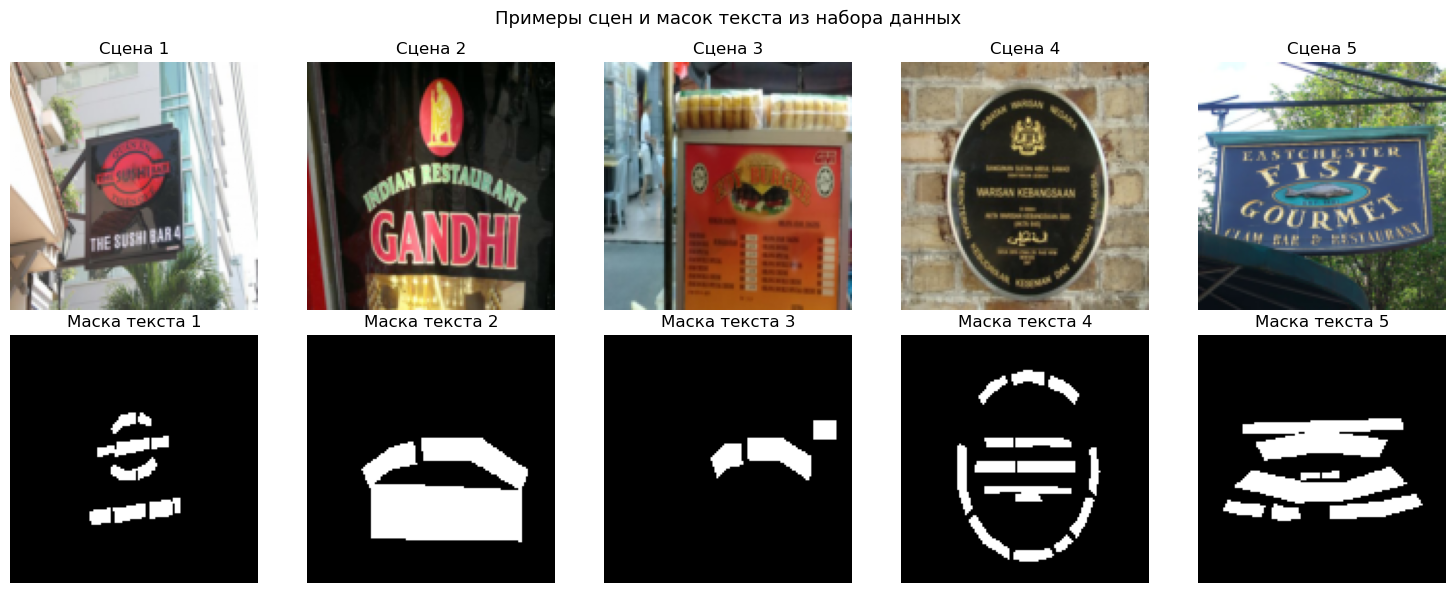

Средняя доля пикселей текста от общей площади изображения: 8.73%
(иллюстрирует выраженный дисбаланс классов, описанный в теории)


In [26]:
if X_train is not None and len(X_train) > 0:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for i in range(5):
        axes[0, i].imshow(X_train[i])
        axes[0, i].set_title(f'Сцена {i+1}')
        axes[0, i].axis('off')
        axes[1, i].imshow(y_train[i, :, :, 0], cmap='gray')
        axes[1, i].set_title(f'Маска текста {i+1}')
        axes[1, i].axis('off')
    plt.suptitle('Примеры сцен и масок текста из набора данных', fontsize=13)
    plt.tight_layout()
    plt.show()

    text_ratio = y_train.mean()
    print(f'Средняя доля пикселей текста от общей площади изображения: {text_ratio:.2%}')
    print('(иллюстрирует выраженный дисбаланс классов, описанный в теории)')

Маски грубые: это закрашенные области вокруг слов, а не контуры букв. На сцене 2 слово «GANDHI» перекрыто широкой коробкой, на сцене 3 размечены только отдельные фрагменты меню, часть текста остаётся без маски. Для лабораторной это допустимо, но Dice и IoU на проверке будут ограничены сверху такой разметкой.

---
## Шаг 6. Архитектура U-Net на Keras

Обратите внимание на компактность определения архитектуры по сравнению
с реализацией на PyTorch: слои соединяются напрямую
через функциональный интерфейс Keras.

In [27]:
def double_conv_block(x, n_filters):
    """Два последовательных свёрточных слоя 3x3 с нормализацией и функцией активации ReLU."""
    x = layers.Conv2D(n_filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(n_filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return x


def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), base_filters=16):
    inputs = keras.Input(shape=input_shape)

    # Сжимающий путь
    e1 = double_conv_block(inputs, base_filters)
    p1 = layers.MaxPooling2D(2)(e1)
    e2 = double_conv_block(p1, base_filters * 2)
    p2 = layers.MaxPooling2D(2)(e2)
    e3 = double_conv_block(p2, base_filters * 4)
    p3 = layers.MaxPooling2D(2)(e3)
    e4 = double_conv_block(p3, base_filters * 8)

    # Расширяющий путь с соединениями быстрого доступа
    u3 = layers.Conv2DTranspose(base_filters * 4, 2, strides=2, padding='same')(e4)
    u3 = layers.Concatenate()([u3, e3])
    d3 = double_conv_block(u3, base_filters * 4)

    u2 = layers.Conv2DTranspose(base_filters * 2, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, e2])
    d2 = double_conv_block(u2, base_filters * 2)

    u1 = layers.Conv2DTranspose(base_filters, 2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, e1])
    d1 = double_conv_block(u1, base_filters)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(d1)

    return keras.Model(inputs, outputs, name='LightUNet_Keras')


model = build_unet()
model.summary()

Model: "LightUNet_Keras"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 128, 128, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_30 (Conv2D)            │ (None, 128, 128, 16)      │             448 │ input_layer_2[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_28        │ (None, 128, 128, 16)      │              64 │ conv2d_30[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_28 (Activation)    │ (None, 128, 128, 16)      │               0 │ batch_normalization_28[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_31 (Conv2D)            │ (None, 128, 128, 16)      │           2,320 │ activation_28[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_29        │ (None, 128, 128, 16)      │              64 │ conv2d_31[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_29 (Activation)    │ (None, 128, 128, 16)      │               0 │ batch_normalization_29[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_6               │ (None, 64, 64, 16)        │               0 │ activation_29[0][0]        │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_32 (Conv2D)            │ (None, 64, 64, 32)        │           4,640 │ max_pooling2d_6[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_30        │ (None, 64, 64, 32)        │             128 │ conv2d_32[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_30 (Activation)    │ (None, 64, 64, 32)        │               0 │ batch_normalization_30[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_33 (Conv2D)            │ (None, 64, 64, 32)        │           9,248 │ activation_30[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_31        │ (None, 64, 64, 32)        │             128 │ conv2d_33[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_31 (Activation)    │ (None, 64, 64, 32)        │               0 │ batch_normalization_31[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_7               │ (None, 32, 32, 32)        │               

 Total params: 484,849 (1.85 MB)

 Trainable params: 483,441 (1.84 MB)

 Non-trainable params: 1,408 (5.50 KB)

---
## Шаг 7. Функция потерь и метрики (коэффициент Дайса, IoU)

Вследствие выраженного дисбаланса классов (текст занимает малую долю площади
кадра) используем комбинированную функцию потерь: бинарная кросс-энтропия
+ функция потерь Дайса.

In [28]:
def dice_coefficient_metric(y_true, y_pred, epsilon=1e-6):
    y_pred_binary = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred_binary, axis=[1, 2, 3])
    union_sum = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred_binary, axis=[1, 2, 3])
    return tf.reduce_mean((2.0 * intersection + epsilon) / (union_sum + epsilon))


def iou_metric(y_true, y_pred, epsilon=1e-6):
    y_pred_binary = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred_binary, axis=[1, 2, 3])
    union = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred_binary, axis=[1, 2, 3]) - intersection
    return tf.reduce_mean((intersection + epsilon) / (union + epsilon))


def dice_loss(y_true, y_pred, epsilon=1e-6):
    intersection = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    union_sum = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    return 1.0 - tf.reduce_mean((2.0 * intersection + epsilon) / (union_sum + epsilon))


def combined_loss(y_true, y_pred):
    bce = keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + dice_loss(y_true, y_pred)


model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=combined_loss,
    metrics=[dice_coefficient_metric, iou_metric]
)

print('Модель скомпилирована: оптимизатор Adam, комбинированная функция потерь.')
print('Обратите внимание: во всём цикле обучения ниже -- одна команда model.fit(),')
print('в отличие от явного цикла по эпохам и пакетам данных, написанного вручную на PyTorch.')

Модель скомпилирована: оптимизатор Adam, комбинированная функция потерь.
Обратите внимание: во всём цикле обучения ниже -- одна команда model.fit(),
в отличие от явного цикла по эпохам и пакетам данных, написанного вручную на PyTorch.


---
## Шаг 8. Обучение модели

Весь цикл обучения (проход вперёд, вычисление потерь, обратное распространение
ошибки, шаг оптимизации, проверка на валидационной выборке) выполняется
внутри одной команды `model.fit()`.

In [29]:
import time

if X_train is not None and len(X_train) > 0:
    NUM_EPOCHS = 15
    t_start = time.time()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=NUM_EPOCHS,
        batch_size=8,
        verbose=1
    )

    print(f'\nВремя обучения: {time.time() - t_start:.1f} секунд (центральный процессор)')
    print(f'Строк кода для полного цикла обучения: 1 (метод model.fit)')

Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 13s 232ms/step - dice_coefficient_metric: 0.1734 - iou_metric: 0.1009 - loss: 1.7492 - val_dice_coefficient_metric: 0.0338 - val_iou_metric: 0.0176 - val_loss: 1.4654
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 191ms/step - dice_coefficient_metric: 0.2323 - iou_metric: 0.1437 - loss: 1.4766 - val_dice_coefficient_metric: 0.0043 - val_iou_metric: 0.0021 - val_loss: 1.4184
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 196ms/step - dice_coefficient_metric: 0.2879 - iou_metric: 0.1911 - loss: 1.4019 - val_dice_coefficient_metric: 0.0049 - val_iou_metric: 0.0025 - val_loss: 1.4449
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 197ms/step - dice_coefficient_metric: 0.3393 - iou_metric: 0.2380 - loss: 1.3425 - val_dice_coefficient_metric: 0.0834 - val_iou_metric: 0.0472 - val_loss: 1.4823
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - dice_coefficient_metric: 0.3972 - iou_metric: 0.2836 - loss: 1.2827 - val_dice_coefficient_metric: 0.0706 - val_iou_metric: 0.041

---
## Шаг 9. Визуализация кривых обучения

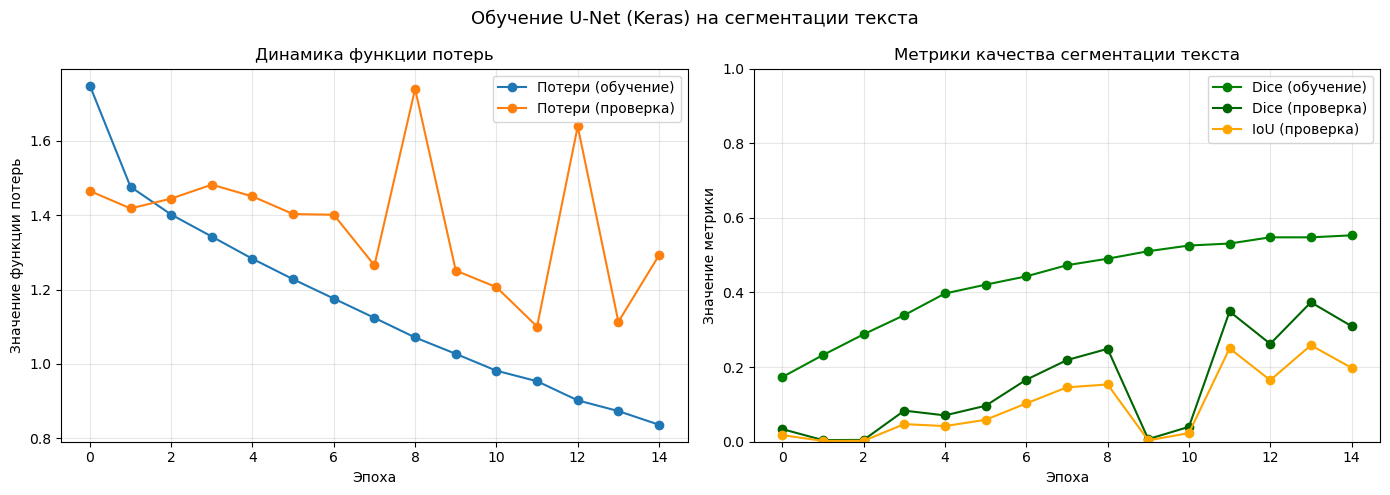

Итоговый Dice на проверочной выборке: 0.3097
Итоговый IoU на проверочной выборке:  0.1980


In [30]:
if X_train is not None and len(X_train) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['loss'], label='Потери (обучение)', marker='o')
    axes[0].plot(history.history['val_loss'], label='Потери (проверка)', marker='o')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Значение функции потерь')
    axes[0].set_title('Динамика функции потерь'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['dice_coefficient_metric'], label='Dice (обучение)', marker='o', color='green')
    axes[1].plot(history.history['val_dice_coefficient_metric'], label='Dice (проверка)', marker='o', color='darkgreen')
    axes[1].plot(history.history['val_iou_metric'], label='IoU (проверка)', marker='o', color='orange')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Значение метрики')
    axes[1].set_title('Метрики качества сегментации текста'); axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[1].set_ylim(0, 1)

    plt.suptitle('Обучение U-Net (Keras) на сегментации текста', fontsize=13)
    plt.tight_layout()
    plt.show()

    final_dice = history.history['val_dice_coefficient_metric'][-1]
    final_iou  = history.history['val_iou_metric'][-1]
    print(f'Итоговый Dice на проверочной выборке: {final_dice:.4f}')
    print(f'Итоговый IoU на проверочной выборке:  {final_iou:.4f}')

---
## Шаг 10. Визуальное сравнение эталонной маски и предсказания модели

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step


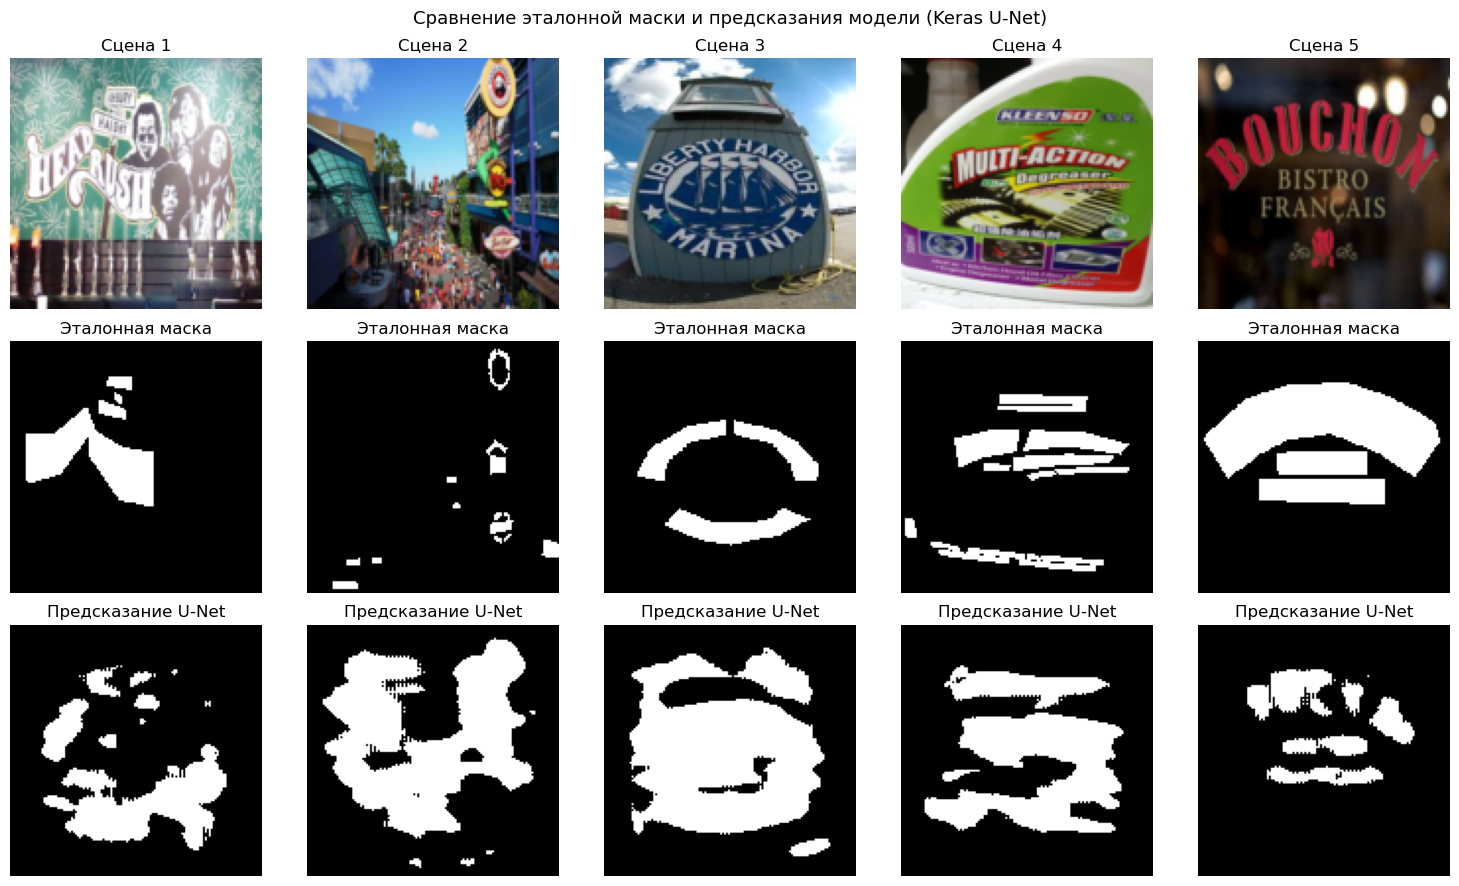

In [31]:
if X_train is not None and len(X_train) > 0:
    predictions = model.predict(X_val[:5])

    fig, axes = plt.subplots(3, 5, figsize=(15, 9))
    for i in range(5):
        axes[0, i].imshow(X_val[i]); axes[0, i].set_title(f'Сцена {i+1}'); axes[0, i].axis('off')
        axes[1, i].imshow(y_val[i, :, :, 0], cmap='gray'); axes[1, i].set_title('Эталонная маска'); axes[1, i].axis('off')
        pred_binary = (predictions[i, :, :, 0] > 0.5).astype(np.float32)
        axes[2, i].imshow(pred_binary, cmap='gray'); axes[2, i].set_title('Предсказание U-Net'); axes[2, i].axis('off')

    plt.suptitle('Сравнение эталонной маски и предсказания модели (Keras U-Net)', fontsize=13)
    plt.tight_layout()
    plt.show()

In [32]:
pred_tr = model.predict(X_train[:25], verbose=0)
pred_va = model.predict(X_val, verbose=0)
pred_va_bn = model(X_val, training=True).numpy()

def stats(name, p, y):
    pb = (p > 0.5).astype(np.float32)
    dice = (2 * (y * pb).sum() + 1e-6) / (y.sum() + pb.sum() + 1e-6)
    print(f'{name}: max={p.max():.3f} mean={p.mean():.3f} доля>0.5={pb.mean():.2%} Dice={dice:.4f}')

stats('train (inference)', pred_tr, y_train[:25])
stats('val   (inference)', pred_va, y_val)
stats('val   (training=True)', pred_va_bn, y_val)
print('Потери по эпохам:', [round(v, 3) for v in history.history['loss']])
print('Dice train по эпохам:', [round(v, 3) for v in history.history['dice_coefficient_metric']])

train (inference): max=1.000 mean=0.373 доля>0.5=31.24% Dice=0.4283
val   (inference): max=1.000 mean=0.360 доля>0.5=28.99% Dice=0.3469
val   (training=True): max=1.000 mean=0.172 доля>0.5=10.04% Dice=0.5646
Потери по эпохам: [1.749, 1.477, 1.402, 1.343, 1.283, 1.228, 1.176, 1.124, 1.071, 1.027, 0.982, 0.953, 0.902, 0.873, 0.836]
Dice train по эпохам: [0.173, 0.232, 0.288, 0.339, 0.397, 0.421, 0.443, 0.473, 0.49, 0.511, 0.526, 0.531, 0.548, 0.548, 0.553]


### Перепишем!

In [33]:
def double_conv_block(x, n_filters):
    """Два последовательных свёрточных слоя 3x3 с нормализацией и функцией активации ReLU."""
    x = layers.Conv2D(n_filters, 3, padding='same')(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(n_filters, 3, padding='same')(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation('relu')(x)
    return x


def build_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3), base_filters=16):
    inputs = keras.Input(shape=input_shape)

    # Сжимающий путь
    e1 = double_conv_block(inputs, base_filters)
    p1 = layers.MaxPooling2D(2)(e1)
    e2 = double_conv_block(p1, base_filters * 2)
    p2 = layers.MaxPooling2D(2)(e2)
    e3 = double_conv_block(p2, base_filters * 4)
    p3 = layers.MaxPooling2D(2)(e3)
    e4 = double_conv_block(p3, base_filters * 8)

    # Расширяющий путь с соединениями быстрого доступа
    u3 = layers.Conv2DTranspose(base_filters * 4, 2, strides=2, padding='same')(e4)
    u3 = layers.Concatenate()([u3, e3])
    d3 = double_conv_block(u3, base_filters * 4)

    u2 = layers.Conv2DTranspose(base_filters * 2, 2, strides=2, padding='same')(d3)
    u2 = layers.Concatenate()([u2, e2])
    d2 = double_conv_block(u2, base_filters * 2)

    u1 = layers.Conv2DTranspose(base_filters, 2, strides=2, padding='same')(d2)
    u1 = layers.Concatenate()([u1, e1])
    d1 = double_conv_block(u1, base_filters)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(d1)

    return keras.Model(inputs, outputs, name='LightUNet_Keras')


model = build_unet()
model.summary()

Model: "LightUNet_Keras"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)    │ (None, 128, 128, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_45 (Conv2D)            │ (None, 128, 128, 16)      │             448 │ input_layer_3[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_42        │ (None, 128, 128, 16)      │              64 │ conv2d_45[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_42 (Activation)    │ (None, 128, 128, 16)      │               0 │ batch_normalization_42[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_46 (Conv2D)            │ (None, 128, 128, 16)      │           2,320 │ activation_42[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_43        │ (None, 128, 128, 16)      │              64 │ conv2d_46[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_43 (Activation)    │ (None, 128, 128, 16)      │               0 │ batch_normalization_43[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_9               │ (None, 64, 64, 16)        │               0 │ activation_43[0][0]        │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_47 (Conv2D)            │ (None, 64, 64, 32)        │           4,640 │ max_pooling2d_9[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_44        │ (None, 64, 64, 32)        │             128 │ conv2d_47[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_44 (Activation)    │ (None, 64, 64, 32)        │               0 │ batch_normalization_44[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_48 (Conv2D)            │ (None, 64, 64, 32)        │           9,248 │ activation_44[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_45        │ (None, 64, 64, 32)        │             128 │ conv2d_48[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ activation_45 (Activation)    │ (None, 64, 64, 32)        │               0 │ batch_normalization_45[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_10              │ (None, 32, 32, 32)        │               

 Total params: 484,849 (1.85 MB)

 Trainable params: 483,441 (1.84 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [34]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-3),
    loss=combined_loss,
    metrics=[dice_coefficient_metric, iou_metric]
)

In [35]:
import time

if X_train is not None and len(X_train) > 0:
    NUM_EPOCHS = 30
    t_start = time.time()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=NUM_EPOCHS,
        batch_size=16,
        verbose=1
    )

    print(f'\nВремя обучения: {time.time() - t_start:.1f} секунд (центральный процессор)')
    print(f'Строк кода для полного цикла обучения: 1 (метод model.fit)')

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 465ms/step - dice_coefficient_metric: 0.2048 - iou_metric: 0.1247 - loss: 1.6344 - val_dice_coefficient_metric: 0.0382 - val_iou_metric: 0.0205 - val_loss: 1.5095
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 407ms/step - dice_coefficient_metric: 0.2010 - iou_metric: 0.1347 - loss: 1.3306 - val_dice_coefficient_metric: 0.0343 - val_iou_metric: 0.0193 - val_loss: 1.3373
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 395ms/step - dice_coefficient_metric: 0.2064 - iou_metric: 0.1402 - loss: 1.2299 - val_dice_coefficient_metric: 0.2097 - val_iou_metric: 0.1427 - val_loss: 1.2197
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 390ms/step - dice_coefficient_metric: 0.3153 - iou_metric: 0.2216 - loss: 1.1282 - val_dice_coefficient_metric: 0.2258 - val_iou_metric: 0.1572 - val_loss: 1.1748
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 396ms/step - dice_coefficient_metric: 0.3494 - iou_metric: 0.2510 - loss: 1.0519 - val_dice_coefficient_metric: 0.2478 - val_iou_metric: 0.172

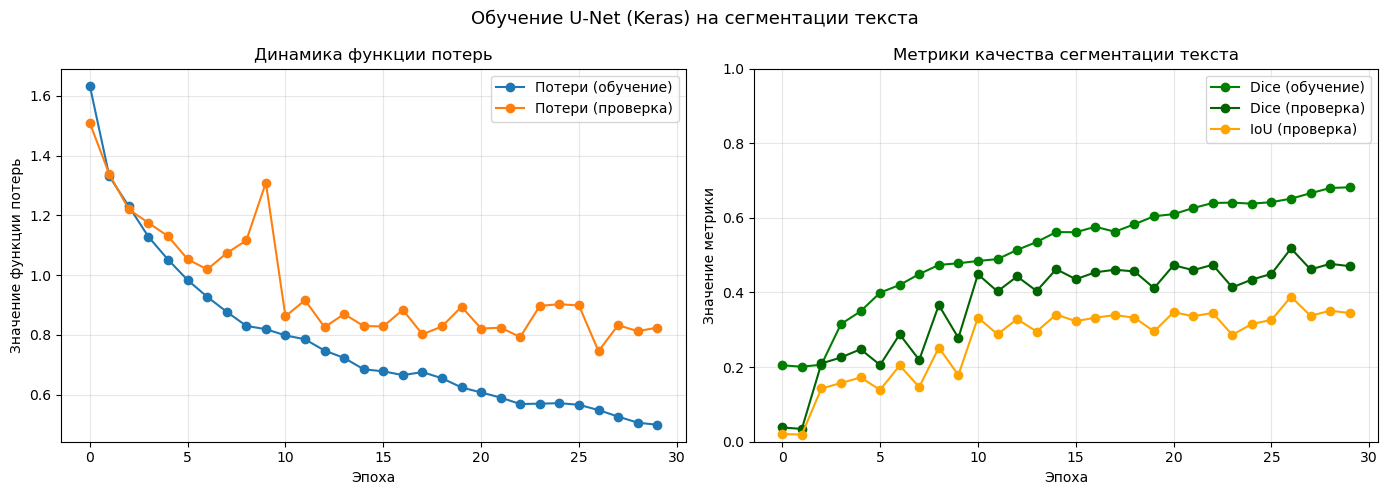

Итоговый Dice на проверочной выборке: 0.4705
Итоговый IoU на проверочной выборке:  0.3448


In [36]:
if X_train is not None and len(X_train) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['loss'], label='Потери (обучение)', marker='o')
    axes[0].plot(history.history['val_loss'], label='Потери (проверка)', marker='o')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Значение функции потерь')
    axes[0].set_title('Динамика функции потерь'); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['dice_coefficient_metric'], label='Dice (обучение)', marker='o', color='green')
    axes[1].plot(history.history['val_dice_coefficient_metric'], label='Dice (проверка)', marker='o', color='darkgreen')
    axes[1].plot(history.history['val_iou_metric'], label='IoU (проверка)', marker='o', color='orange')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Значение метрики')
    axes[1].set_title('Метрики качества сегментации текста'); axes[1].legend(); axes[1].grid(alpha=0.3)
    axes[1].set_ylim(0, 1)

    plt.suptitle('Обучение U-Net (Keras) на сегментации текста', fontsize=13)
    plt.tight_layout()
    plt.show()

    final_dice = history.history['val_dice_coefficient_metric'][-1]
    final_iou  = history.history['val_iou_metric'][-1]
    print(f'Итоговый Dice на проверочной выборке: {final_dice:.4f}')
    print(f'Итоговый IoU на проверочной выборке:  {final_iou:.4f}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step


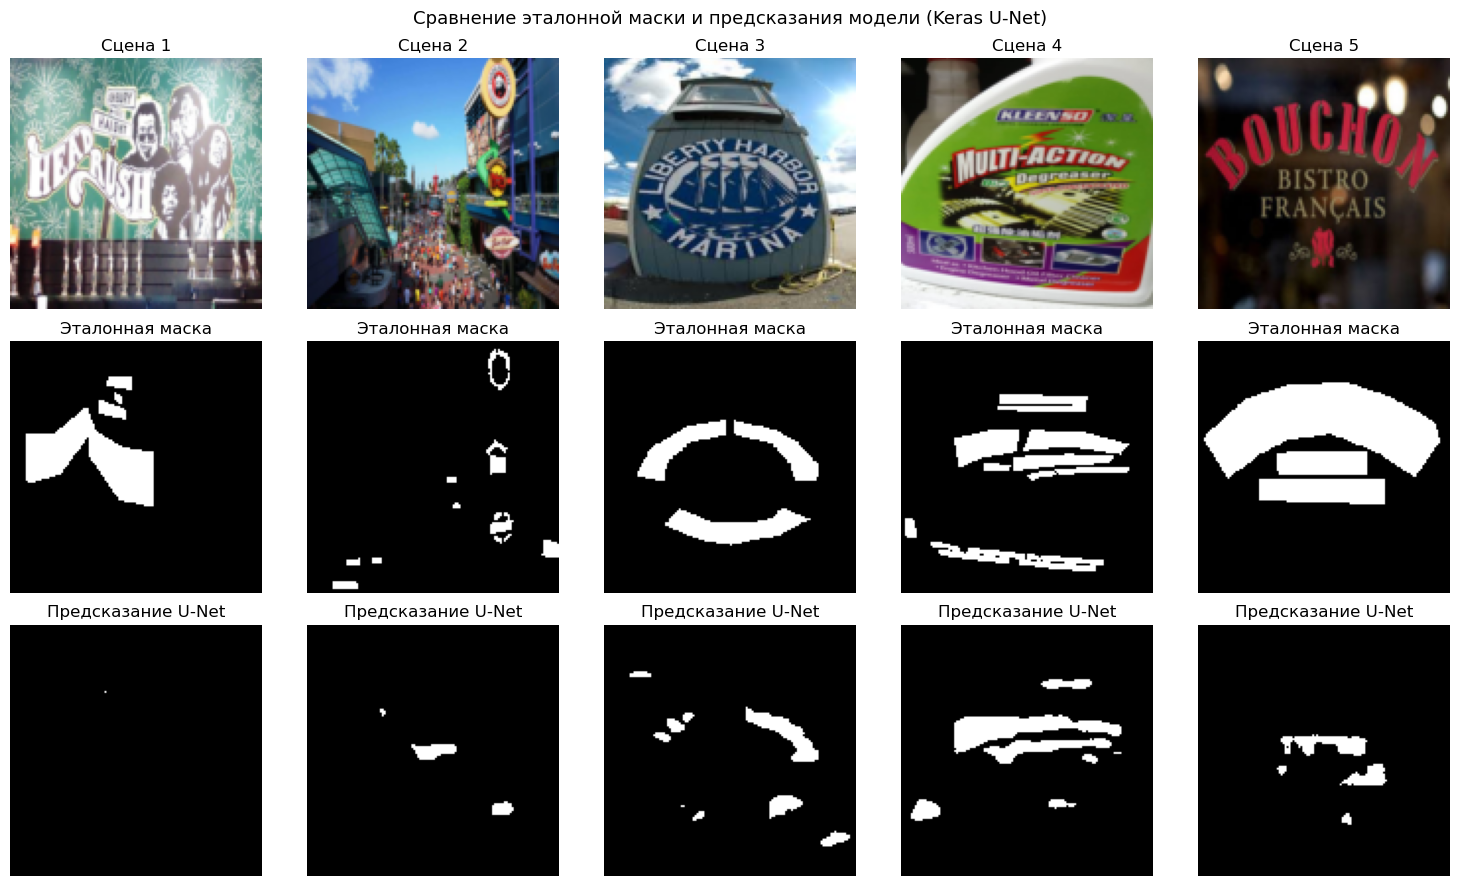

In [37]:
if X_train is not None and len(X_train) > 0:
    predictions = model.predict(X_val[:5])

    fig, axes = plt.subplots(3, 5, figsize=(15, 9))
    for i in range(5):
        axes[0, i].imshow(X_val[i]); axes[0, i].set_title(f'Сцена {i+1}'); axes[0, i].axis('off')
        axes[1, i].imshow(y_val[i, :, :, 0], cmap='gray'); axes[1, i].set_title('Эталонная маска'); axes[1, i].axis('off')
        pred_binary = (predictions[i, :, :, 0] > 0.5).astype(np.float32)
        axes[2, i].imshow(pred_binary, cmap='gray'); axes[2, i].set_title('Предсказание U-Net'); axes[2, i].axis('off')

    plt.suptitle('Сравнение эталонной маски и предсказания модели (Keras U-Net)', fontsize=13)
    plt.tight_layout()
    plt.show()

---
## Шаг 11. Мини-опрос и обсуждение: Keras против PyTorch

Сравнение опыта разработки на основании выполненных лабораторных работ
(занятие 5-6 -- PyTorch, занятие 7 -- Keras).

In [24]:
comparison_table = {
    'Критерий': [
        'Число строк кода для определения архитектуры U-Net',
        'Число строк кода для полного цикла обучения',
        'Необходимость явного вызова backward() и optimizer.step()',
        'Автоматическое ведение истории обучения (loss, метрики)',
        'Простота встраивания собственной метрики',
        'Прозрачность промежуточных вычислений для отладки',
    ],
    'PyTorch (занятие 5-6)': [
        '~25 строк (класс с методом forward)',
        '~20-25 строк (явный цикл по эпохам и пакетам)',
        'Да, требуется',
        'Нет, реализуется вручную (список history)',
        'Требуется отдельная функция + ручной вызов',
        'Высокая (каждый шаг виден в коде)',
    ],
    'Keras (занятие 7)': [
        '~20 строк (функциональный API)',
        '1 строка (model.fit)',
        'Нет, скрыто внутри fit()',
        'Да, встроено (объект history)',
        'Передаётся в compile(metrics=[...])',
        'Ниже (внутренние шаги скрыты библиотекой)',
    ]
}

import pandas as pd
df_comparison = pd.DataFrame(comparison_table)
print(df_comparison.to_string(index=False))
print()
print('Вопросы для обсуждения на занятии:')
print('1. В каком из двух подходов было легче найти и исправить ошибку в вычислении метрики?')
print('2. Какой из фреймворков дал более быстрое понимание происходящего внутри цикла обучения?')
print('3. Какой подход предпочтителен для быстрого прототипирования, а какой -- для')
print('   тонкой настройки нестандартной схемы обучения?')

                                                 Критерий                         PyTorch (занятие 5-6)                         Keras (занятие 7)
       Число строк кода для определения архитектуры U-Net           ~25 строк (класс с методом forward)            ~20 строк (функциональный API)
              Число строк кода для полного цикла обучения ~20-25 строк (явный цикл по эпохам и пакетам)                      1 строка (model.fit)
Необходимость явного вызова backward() и optimizer.step()                                 Да, требуется                  Нет, скрыто внутри fit()
  Автоматическое ведение истории обучения (loss, метрики)     Нет, реализуется вручную (список history)             Да, встроено (объект history)
                 Простота встраивания собственной метрики    Требуется отдельная функция + ручной вызов       Передаётся в compile(metrics=[...])
        Прозрачность промежуточных вычислений для отладки             Высокая (каждый шаг виден в коде) Ниже (внутренние шаг

---
## Итоговая сводка

| Компонент | Реализация в ноутбуке |
|---|---|
| Набор данных | Total-Text: фотографии сцен с горизонтальным, ориентированным и изогнутым текстом; подвыборка `TRAIN_SIZE` изображений из Train и `VAL_SIZE` из Test |
| Разметка | Готовые бинарные маски областей текста (`Text_Region_Mask`, PNG): текст — 1, фон — 0 |
| Предобработка | Приведение изображений и масок к размеру `IMG_SIZE × IMG_SIZE`, нормировка изображений в диапазон [0, 1] |
| Библиотека | Keras (TensorFlow), выполнение на центральном процессоре |
| Архитектура | U-Net, функциональный API, базовое число каналов 16, `BatchNormalization(momentum=0.9)` |
| Функция потерь | Сумма бинарной кросс-энтропии и функции потерь Дайса |
| Метрики | Коэффициент Дайса и IoU (пользовательские функции Keras) |
| Сопоставление фреймворков | Таблица различий Keras и PyTorch по итогам двух лабораторных работ |

**Что показала работа.** Текст занимает небольшую долю пикселей, поэтому используется комбинированная функция потерь. Метрики на проверке всегда считаются в режиме предсказания (`training=False`). Если они близки к нулю при хорошем качестве на обучении, причина может быть в статистиках слоёв нормализации (см. задание 4).

---
## Домашнее задание

1. **Основное.** Реализуйте ту же архитектуру U-Net на Keras с использованием класса `keras.Model` через наследование (объектно-ориентированный подход, переопределение метода `call()`), а не функциональный API, использованный в ноутбуке. Убедитесь, что при том же `SEED` и числе эпох метрики Dice и IoU сопоставимы с результатом из ноутбука. Сравните читаемость получившегося кода с функциональным подходом.

2. **Эксперимент с балансировкой классов.** Постройте вариант функции потерь с явным весовым коэффициентом для класса «текст» (например, весовая бинарная кросс-энтропия с весом 5–10 для текстовых пикселей). Сравните значения Dice и IoU на проверочной выборке с результатом комбинированной функции потерь из ноутбука. Объясните, как выбранный вес связан с долей пикселей текста, полученной в Шаге 4.

3. **Анализ ошибок по изображениям.** Для каждого изображения проверочной выборки отдельно посчитайте Dice и долю пикселей текста в эталонной маске. Разделите изображения на две группы по медиане этой доли и сравните средний Dice групп. Постройте диаграмму рассеяния «доля текста — Dice». Объясните причины различий, опираясь на примеры из Шагов 5 и 10 (мелкие надписи, изогнутый текст, неполная разметка).

4. **(Дополнительно)** Исследуйте влияние параметра `momentum` слоя `BatchNormalization`. Обучите модели со значениями 0.99 (по умолчанию) и 0.9. Для каждой посчитайте Dice на проверочной выборке в режиме `training=False` и по батчевой статистике (`model(X_val, training=True)`). Объясните, почему при малом числе шагов обучения результаты в двух режимах расходятся.

5. **(Дополнительно)** Составьте письменный отчёт на одну страницу по итогам мини-опроса из Шага 11: сформулируйте собственную позицию, какой из двух фреймворков вы предпочли бы использовать для а) учебного проекта, б) исследовательской работы с нестандартной архитектурой, и обоснуйте выбор. Приведите хотя бы один пример из выполненных лабораторных работ.